In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


dataset

In [2]:
df = pd.read_csv(r"D:\AML3303\maplefreight_delivery_delay_dataset (1).csv")

#first five rows
print("First five rows of the dataset:")
display(df.head())

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

First five rows of the dataset:


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,...,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,...,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,...,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,...,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,...,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,...,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


Number of rows: 6035
Number of columns: 23


In [3]:
df.info()

# Count missing values
print("\nMissing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Count completely duplicated rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check for repeated shipment IDs
print("Repeated shipment IDs:", df["shipment_id"].duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

delivered_late
0    4793
1    1242
Name: count, dtype: int64


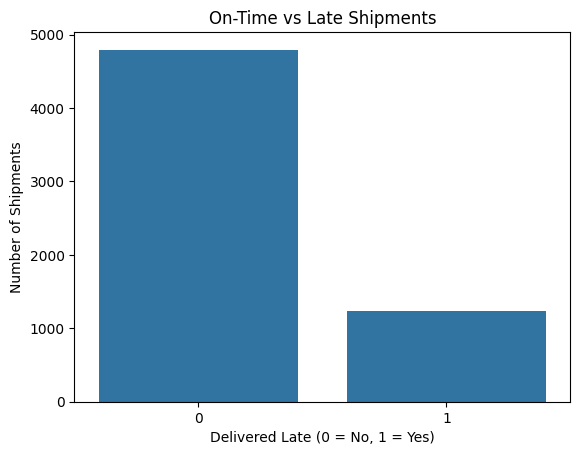

In [4]:

# Count on-time and late shipments
print(df["delivered_late"].value_counts())

# Plot the target distribution
sns.countplot(data=df, x="delivered_late")
plt.title("On-Time vs Late Shipments")
plt.xlabel("Delivered Late (0 = No, 1 = Yes)")
plt.ylabel("Number of Shipments")
plt.show()


carrier
Contract Owner-Op     35.897436
PrairieLine           26.502146
QuebecExpress         22.402597
NorthStar Carriers    21.993127
MapleFreight Fleet    12.881639
Name: delivered_late, dtype: float64


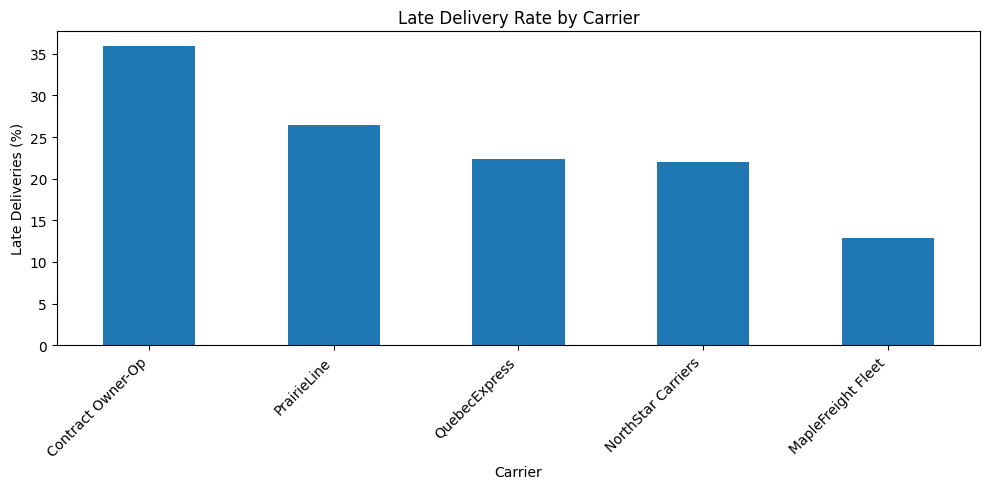

In [5]:

# Calculate the percentage of shipments delivered late by carrier
carrier_delay = (
    df.groupby("carrier")["delivered_late"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(carrier_delay)

carrier_delay.plot(kind="bar", figsize=(10, 5))
plt.title("Late Delivery Rate by Carrier")
plt.xlabel("Carrier")
plt.ylabel("Late Deliveries (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


weather_condition
Storm    46.315789
Snow     33.486766
Fog      21.276596
Rain     20.870871
Clear    14.045699
Name: delivered_late, dtype: float64


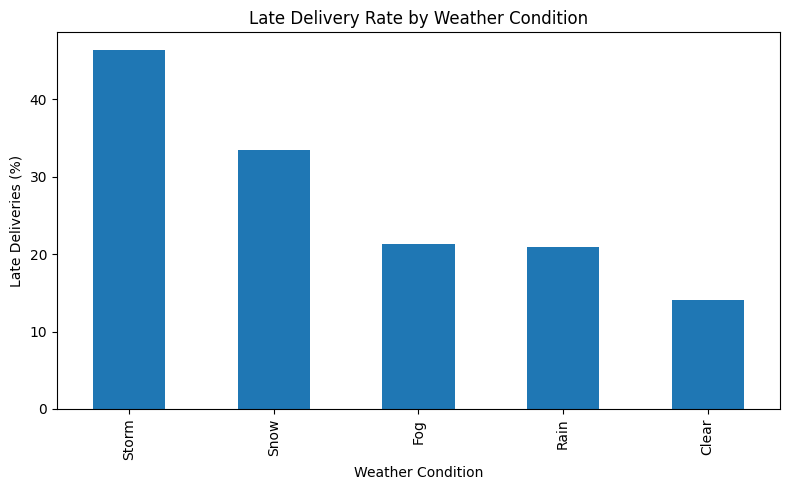

In [6]:

weather_delay = (
    df.groupby("weather_condition")["delivered_late"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print(weather_delay)

weather_delay.plot(kind="bar", figsize=(8, 5))
plt.title("Late Delivery Rate by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Late Deliveries (%)")
plt.tight_layout()
plt.show()


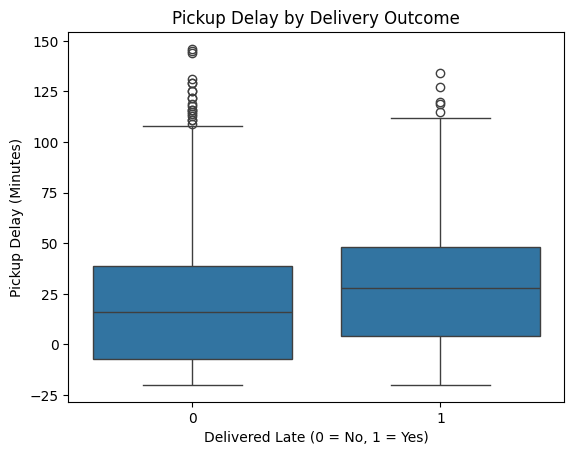

In [7]:

sns.boxplot(
    data=df,
    x="delivered_late",
    y="pickup_delay_minutes"
)
plt.title("Pickup Delay by Delivery Outcome")
plt.xlabel("Delivered Late (0 = No, 1 = Yes)")
plt.ylabel("Pickup Delay (Minutes)")
plt.show()


In [8]:

# Preserve the original data
raw_df = df.copy()

# Remove completely duplicated rows
df = df.drop_duplicates().copy()

print("Original rows:", len(raw_df))
print("Rows after deduplication:", len(df))

# Check the target
print(df["delivered_late"].value_counts(dropna=False))

# Check repeated shipment IDs
print(
    "Repeated shipment IDs:",
    df["shipment_id"].duplicated().sum()
)


Original rows: 6035
Rows after deduplication: 6003
delivered_late
0    4768
1    1235
Name: count, dtype: int64
Repeated shipment IDs: 3


In [9]:

# Summary of numerical variables
display(df.describe().T)

# Display distinct category values
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))


,count,mean,std,min,25%,50%,75%,max
shipment_month,6003.0,6.541229,3.448158,1.00,4.0000,7.000,10.000,12.00
distance_km,6003.0,632.131901,319.362781,80.50,398.4500,571.100,804.500,2556.70
weight_kg,6003.0,6959.216142,83977.028212,30.00,495.9500,827.100,1286.300,2999300.00
num_stops,6003.0,2.474596,1.707193,0.00,1.0000,2.000,4.000,5.00
is_cross_border,6003.0,0.112610,0.316142,0.00,0.0000,0.000,0.000,1.00
scheduled_transit_hours,6003.0,10.497223,4.760570,1.00,7.0600,9.830,13.170,37.40
pickup_delay_minutes,6003.0,20.347826,30.605033,-20.00,-6.0000,18.000,41.000,146.00
driver_experience_years,5793.0,6.505369,4.661821,0.20,3.2000,5.400,8.700,35.00
vehicle_age_years,6003.0,5.492570,3.435431,0.10,3.0000,4.800,7.200,20.00
traffic_index,5883.0,55.145113,17.597015,5.00,43.3000,55.000,67.200,100.00



shipment_id:
shipment_id
SHP-103022    2
SHP-101906    2
SHP-102476    2
SHP-103848    1
SHP-102827    1
SHP-105254    1
SHP-102719    1
SHP-105198    1
SHP-101857    1
SHP-102142    1
SHP-103123    1
SHP-100691    1
SHP-101694    1
SHP-102224    1
SHP-103308    1
SHP-101568    1
SHP-104140    1
SHP-100887    1
SHP-103326    1
SHP-102074    1
Name: count, dtype: int64

origin_city:
origin_city
Toronto ON        1583
Montreal QC       1014
Mississauga ON    1012
Calgary AB         759
Ottawa ON          726
London ON          458
Winnipeg MB        451
Name: count, dtype: int64

destination_city:
destination_city
Sudbury ON        636
Toronto ON        636
Regina SK         633
Winnipeg MB       610
Hamilton ON       600
Quebec City QC    594
Edmonton AB       589
Montreal QC       584
Calgary AB        575
Ottawa ON         546
Name: count, dtype: int64

carrier:
carrier
MapleFreight Fleet    2378
NorthStar Carriers    1158
PrairieLine            927
QuebecExpress          917
Contrac

C:\Users\kaurm\AppData\Local\Temp\ipykernel_20292\2617733514.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [10]:

# Remove records without a known target
df = df.dropna(subset=["delivered_late"]).copy()

# Keep only valid binary target values
df = df[df["delivered_late"].isin([0, 1])].copy()

# Remove duplicate records again if needed
df = df.drop_duplicates().copy()

# Target variable
y = df["delivered_late"].astype(int)

# Input features
X = df.drop(
    columns=[
        "delivered_late",
        "shipment_id",
        "actual_transit_hours"
    ]
)

print("Feature rows and columns:", X.shape)
print("Target shape:", y.shape)


Feature rows and columns: (6003, 20)
Target shape: (6003,)


In [11]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 4802
Testing rows: 1201


To handle missing values and convert text categories into numbers.

In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['shipment_month', 'distance_km', 'weight_kg', 'num_stops', 'is_cross_border', 'scheduled_transit_hours', 'pickup_delay_minutes', 'driver_experience_years', 'vehicle_age_years', 'traffic_index', 'route_congestion_score', 'prior_late_deliveries_30d', 'fuel_cost_cad']
Categorical features: ['origin_city', 'destination_city', 'carrier', 'service_level', 'goods_type', 'customer_priority_tier', 'weather_condition']


In [13]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

print("Baseline accuracy:",
      accuracy_score(y_test, baseline_predictions))

print("Baseline precision:",
      precision_score(y_test, baseline_predictions, zero_division=0))

print("Baseline recall:",
      recall_score(y_test, baseline_predictions, zero_division=0))

print("Baseline F1-score:",
      f1_score(y_test, baseline_predictions, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, baseline_predictions))


Baseline accuracy: 0.794338051623647
Baseline precision: 0.0
Baseline recall: 0.0
Baseline F1-score: 0.0

Confusion matrix:
[[954   0]
 [247   0]]


In [14]:

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_test)

print(classification_report(
    y_test,
    logistic_predictions,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, logistic_predictions))


              precision    recall  f1-score   support

           0       0.92      0.75      0.83       954
           1       0.44      0.74      0.55       247

    accuracy                           0.75      1201
   macro avg       0.68      0.75      0.69      1201
weighted avg       0.82      0.75      0.77      1201

Confusion matrix:
[[716 238]
 [ 63 184]]


In [15]:

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_predictions))


              precision    recall  f1-score   support

           0       0.81      1.00      0.89       954
           1       0.87      0.08      0.15       247

    accuracy                           0.81      1201
   macro avg       0.84      0.54      0.52      1201
weighted avg       0.82      0.81      0.74      1201

Confusion matrix:
[[951   3]
 [227  20]]


In [16]:

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)

print(classification_report(
    y_test,
    rf_predictions,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, rf_predictions))


              precision    recall  f1-score   support

           0       0.81      1.00      0.89       954
           1       0.87      0.08      0.15       247

    accuracy                           0.81      1201
   macro avg       0.84      0.54      0.52      1201
weighted avg       0.82      0.81      0.74      1201

Confusion matrix:
[[951   3]
 [227  20]]


In [17]:

def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

results = [
    {
        "Model": "Majority Baseline",
        "Accuracy": accuracy_score(y_test, baseline_predictions),
        "Precision": precision_score(
            y_test, baseline_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, baseline_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, baseline_predictions, zero_division=0
        )
    },
    evaluate_model(
        "Logistic Regression", logistic_model, X_test, y_test
    ),
    evaluate_model(
        "Random Forest", random_forest_model, X_test, y_test
    )
]

results_df = pd.DataFrame(results)
display(results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score
0,Majority Baseline,0.794,0.000,0.000,0.000
1,Logistic Regression,0.749,0.436,0.745,0.550
2,Random Forest,0.808,0.870,0.081,0.148


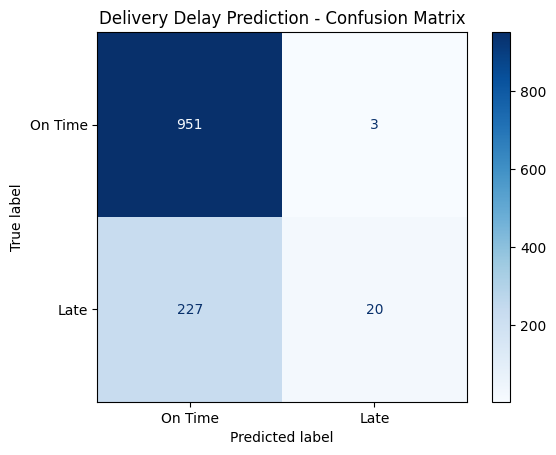

In [18]:

from sklearn.metrics import ConfusionMatrixDisplay

candidate_model = random_forest_model  # Change after comparing results
candidate_predictions = candidate_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    candidate_predictions,
    display_labels=["On Time", "Late"],
    cmap="Blues"
)

plt.title("Delivery Delay Prediction - Confusion Matrix")
plt.show()


,Feature,Importance
5,numeric__scheduled_transit_hours,0.083278
9,numeric__traffic_index,0.079868
1,numeric__distance_km,0.071860
6,numeric__pickup_delay_minutes,0.067071
10,numeric__route_congestion_score,0.062011
7,numeric__driver_experience_years,0.059088
8,numeric__vehicle_age_years,0.053599
2,numeric__weight_kg,0.053310
12,numeric__fuel_cost_cad,0.051405
3,numeric__num_stops,0.041085


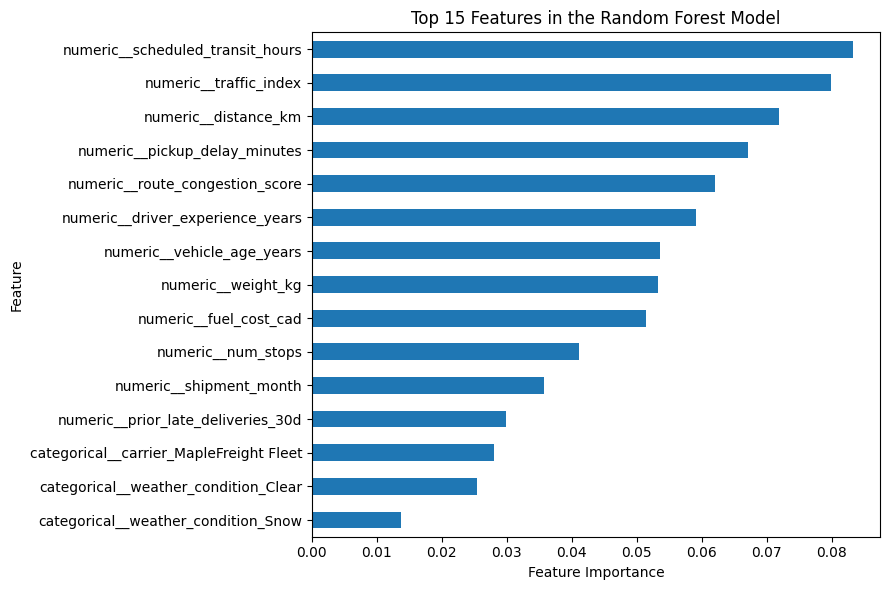

In [19]:

# Get the trained Random Forest and transformed feature names
rf = random_forest_model.named_steps["classifier"]
feature_names = (
    random_forest_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

importance_df.head(15).sort_values(
    "Importance"
).plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 6)
)

plt.title("Top 15 Features in the Random Forest Model")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


In [20]:
pip install python-dotenv

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [21]:

import os
import requests
from dotenv import load_dotenv

load_dotenv("D:\AML3303\.env")

webhook_url = os.getenv("SLACK_WEBHOOK_URL")

if not webhook_url:
    raise ValueError(
        "Slack webhook is missing. Check your local .env file."
    )


<>:5: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
<>:5: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
C:\Users\kaurm\AppData\Local\Temp\ipykernel_20292\3264261309.py:5: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
  load_dotenv("D:\AML3303\.env")
C:\Users\kaurm\AppData\Local\Temp\ipykernel_20292\3264261309.py:5: SyntaxWarning: "\A" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\A"? A raw string is also an option.
  load_dotenv("D:\AML3303\.env")


ValueError: Slack webhook is missing. Check your local .env file.

In [ ]:

def send_slack_alert(webhook_url, message):
    response = requests.post(
        webhook_url,
        json={"text": message},
        timeout=15
    )
    response.raise_for_status()
    print("Slack message sent successfully.")


In [ ]:

test_message = {
    "text": (
        "🧪 *MapleFreight Test Alert*\n"
        "This is a test message from the AML 3303 "
        "Delivery Delay Prediction project. "
        "Slack integration is being tested."
    )
}

response = requests.post(
    webhook_url,
    json=test_message,
    timeout=15
)

response.raise_for_status()

if response.text.strip() == "ok":
    print("Test message sent successfully!")
else:
    print("Slack responded:", response.text)


Test message sent successfully!
